# A short tutorial about Fuzzy Time Series
Prof. Msc. Petrônio Cândido L. Silva

[pyFTS - Fuzzy Time Series for Python](http://pyfts.github.io/pyFTS/)

[MINDS - Machine Intelligence and Data Science Lab  ](http://www.minds.eng.ufmg.br/)



<center>
<table><tr><td> <a href="http://www.minds.eng.ufmg.br/"><img src="https://github.com/petroniocandido/pyFTS/raw/master/img/minds_logo_medium.jpeg" alt="MINDS - Machine Intelligence and Data Science Lab" width="100"/></a></td> 
  <td>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;</td>
<td><a href="https://pyfts.github.io/pyFTS/"><img src="https://github.com/PYFTS/pyFTS/raw/master/img/logo_medium.png" alt="pyFTS - Fuzzy Time Series for Python" width="100"/></a></td>
</tr>
</table>
</center>


## Install pyFTS library

In [1]:
!pip3 install -U git+https://github.com/PYFTS/pyFTS

  Cloning https://github.com/PYFTS/pyFTS to /tmp/pip-req-build-flahfvb1
  Running command git clone --filter=blob:none --quiet https://github.com/PYFTS/pyFTS /tmp/pip-req-build-flahfvb1
  Resolved https://github.com/PYFTS/pyFTS to commit 4e0ee7cdd9fc9a8ac9170c0c3496536ef0378cb7
  Preparing metadata (setup.py) ... done
  Created wheel for pyFTS: filename=pyFTS-1.7-py3-none-any.whl size=219429 sha256=358844a1116fdb0a2157e3abcc3e769193545af8d656d5360e2c09a9966bbdfe
  Stored in directory: /tmp/pip-ephem-wheel-cache-52gjwe_p/wheels/3f/88/d0/b42bbeda9160113cbb04e525e61c43fbbda50d31d964fe31ef
Successfully built pyFTS


## Other common imports

In [2]:
import warnings
warnings.filterwarnings('ignore')


import matplotlib.pylab as plt

%pylab inline

Populating the interactive namespace from numpy and matplotlib


## Data loading

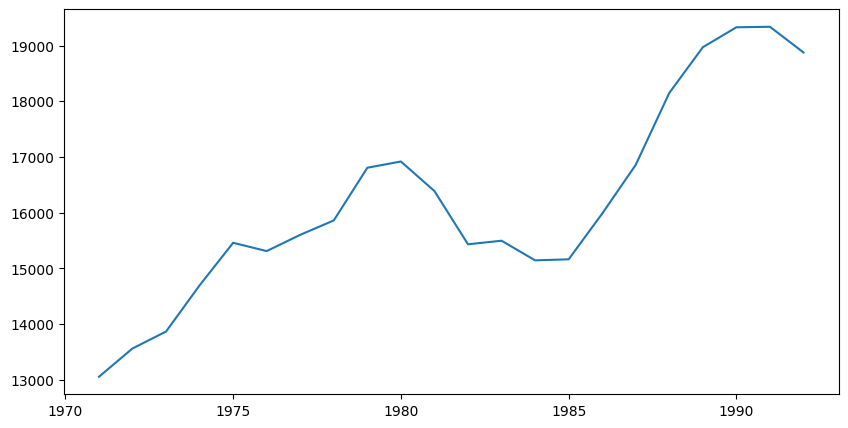

In [3]:
from pyFTS.data import Enrollments

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=[10,5])

df = Enrollments.get_dataframe()
plot(df['Year'],df['Enrollments'])

data = df['Enrollments'].values

## Training procedure

### Definition of the Universe of Discourse U & Linguistic variable creation

The Universe of Discourse (U) partitioners are responsible for identifying U, split the partitions and create their fuzzy sets. There are several ways to partition U and this has a direct impact on the accuracy of the predictive model.

For this example we are using grid partitioning, where all sets are equal. The default membership function is triangular.

**Các bộ phân hoạch của Vũ trụ luận (Universe of Discourse – U) có nhiệm vụ xác định miền giá trị U, chia U thành các phân vùng và tạo ra các tập mờ tương ứng. Có nhiều cách khác nhau để phân hoạch U, và việc lựa chọn phương pháp phân hoạch này có ảnh hưởng trực tiếp đến độ chính xác của mô hình dự báo.**

**Trong ví dụ này, chúng tôi sử dụng phương pháp phân hoạch dạng lưới (grid partitioning), trong đó tất cả các tập mờ đều có kích thước bằng nhau. Hàm thành viên mặc định được sử dụng là hàm tam giác (triangular).**

**Partitioner là thành phần cốt lõi của FTS:**
* Xác định U = [min, max]
* Chia U thành các khoảng
* Sinh ra các tập mờ  A0, A1,...

**Grid partitioning:**
* Chia đều U
* Dễ diễn giải
* Ít tham số
* Phù hợp ví dụ minh hoạ và baseline

**Triangular membership function:**

* Đơn giản
* Có chồng lấn tuyến tính
* Phản ánh tốt quá trình chuyển tiếp mờ


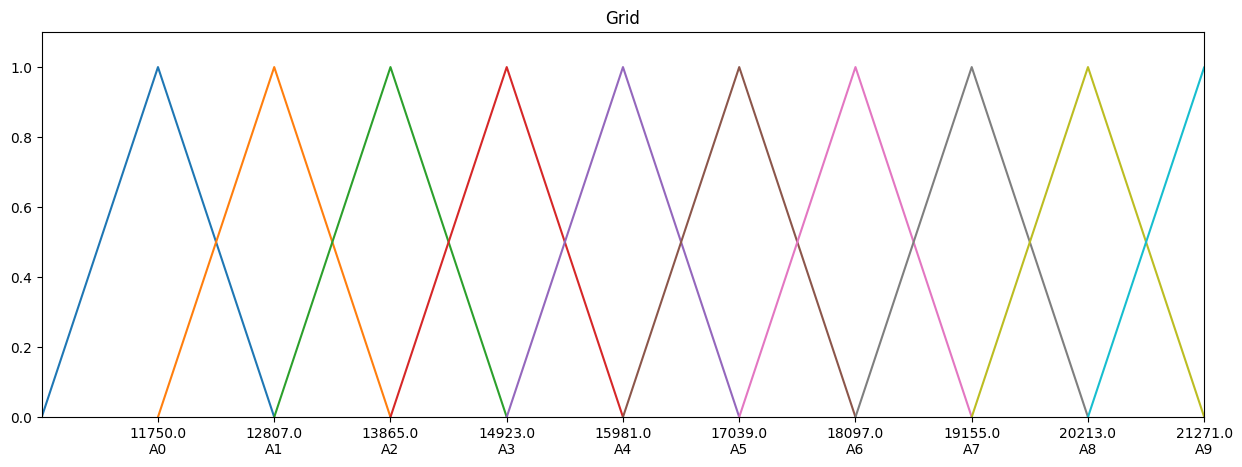

In [4]:
from pyFTS.partitioners import Grid

fs = Grid.GridPartitioner(data=data,npart=10)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=[15,5])

fs.plot(ax)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

labels = model.partitioner.ordered_sets

plt.figure(figsize=(22,8))

for i, k in enumerate(labels):
    fs = model.sets[k]

    # Lấy khoảng của trimf
    a = fs.lower
    b = fs.centroid
    c = fs.upper

    # Trục x cho từng tam giác
    x = np.linspace(a, c, 300)
    y = [fs.membership(v) for v in x]

    # Vẽ tam giác
    plt.plot(x, y, linewidth=2, label=k)

    # Vẽ centroid
    plt.axvline(b, linestyle="--", alpha=0.4)

    # Ghi chú khoảng (chỉ ghi trên đỉnh để đỡ rối)
    plt.text(b, 1.02, f"{k}\n[{a:.0f}, {b:.0f}, {c:.0f}]",
             ha="center", va="bottom", fontsize=8)

# Format hình
plt.xlabel("Value (Universe of Discourse)")
plt.ylabel("Membership degree μ(x)")
plt.title("Triangular Membership Functions (A0–A9)")
plt.ylim(0, 1.15)
plt.legend(ncol=5, fontsize=8)
plt.grid(alpha=0.3)

plt.show()


NameError: name 'model' is not defined

### Fuzzyfication

This is demo-only, and you do not need to explicitly run it. This entire process runs automatically within the fit function, which trains the model.

In [ ]:

fuzzyfied = fs.fuzzyfy(data, method='maximum', mode='sets')

fuzzyfied

### Temporal patterns

This is demo-only, and you do not need to explicitly run it. This entire process runs automatically within the fit function, which trains the model.

In [ ]:
from pyFTS.common import FLR

patterns = FLR.generate_non_recurrent_flrs(fuzzyfied)

print([str(k) for k in patterns])

# Fuzzification = biến chuỗi số → ma trận μ(Aᵢ, t)

In [ ]:
for k in model.partitioner.ordered_sets:
    fs = model.sets[k]
    print(k, fs.centroid)


In [ ]:
import pandas as pd

labels = model.partitioner.ordered_sets
sets = model.sets

rows = []

for x in data:
    row = {"x": x}
    for k in labels:
        row[k] = sets[k].membership(x)  # <-- CHUẨN, LUÔN LÀ FLOAT
    rows.append(row)

df_mu = pd.DataFrame(rows)
df_mu


**x = 15460**

* A3 = 0.4926
* A4 = 0.5074
  
**➡️ Điểm x nằm giữa b3 và b4**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
sns.heatmap(df_mu[labels].T, cmap="viridis")
plt.xlabel("Time index")
plt.ylabel("Fuzzy set")
plt.title("Fuzzification Membership Heatmap")
plt.show()


### Rule generation

In [ ]:
import pandas as pd
import datetime as _datetime

pd.datetime = _datetime.datetime

from pyFTS.models import chen

model = chen.ConventionalFTS(partitioner=fs)
model.fit(data)
print(model)

Thư viện pyFTS dùng code visualization cũ, chưa tương thích matplotlib mới. Em chỉ điều chỉnh phần hiển thị, không ảnh hưởng rule base hay forecasting

In [ ]:
from pyFTS.common import Util
import matplotlib.pyplot as plt

def safe_draw_sets_on_axis(axis, model, size):
    axis.set_ylim([model.partitioner.min, model.partitioner.max])
    axis.set_yticks(
        [model.sets[k].centroid for k in model.partitioner.ordered_sets]
    )

Util.draw_sets_on_axis = safe_draw_sets_on_axis

Util.plot_rules(
    model,
    size=[15,5],
    rules_by_axis=len(model.partitioner.ordered_sets)
)


##  Forecasting procedure

### Input value fuzzyfication

This is demo-only, and you do not need to explicitly run it. This entire process runs automatically within the fit function, which trains the model.

**Đây chỉ là ví dụ minh hoạ. Bạn không cần tự gọi hay chạy đoạn này, vì toàn bộ các bước (mờ hoá, khớp luật, suy luận) đã được tự động thực hiện bên trong hàm fit khi mô hình được huấn luyện**

In [ ]:

# fuzzyfied = fs.fuzzyfy(18876, method='maximum', mode='sets')

# print(fuzzyfied)

### Find the compatible rules & Defuzzyfy

In [ ]:
model.predict([18876])

## Model's in sample performance 

*“Nếu tôi đưa lại những giá trị cũ cho mô hình,thì nó dự đoán ra cái gì?”*

📌 **Đây gọi là in-sample forecasting**.

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=[15,5])

forecasts = model.predict(data)
forecasts.insert(0,None) #Dự báo tại thời điểm đầu không tồn tại - thêm none để canh trục tg

orig, = plot(data, label="Original data")
pred, = plot(forecasts, label="Forecasts")

legend(handles=[orig, pred])

*=> mô hình Đúng chiều xu hướng (trend consistency)*

👉 Trong hình của bạn:

* Giai đoạn đầu: cả 2 cùng tăng ✔️

* Giai đoạn giữa: cùng giảm nhẹ ✔️

* Giai đoạn cuối: cùng tăng mạnh ✔️

📌 ⇒ Hợp lý, vì luật mờ học đúng hướng chuyển trạng thái.

In [ ]:
import numpy as np

def evaluate_rmse_mae(y_true, y_pred):
    """
    Evaluate RMSE, MAE and their relative percentages (%) for FTS forecasts.
    Automatically ignores None values in predictions.
    """
    y_true_clean = []
    y_pred_clean = []

    for yt, yp in zip(y_true, y_pred):
        if yp is not None:
            y_true_clean.append(yt)
            y_pred_clean.append(yp)

    y_true_clean = np.array(y_true_clean, dtype=float)
    y_pred_clean = np.array(y_pred_clean, dtype=float)

    # Absolute errors
    mae = np.mean(np.abs(y_true_clean - y_pred_clean))
    rmse = np.sqrt(np.mean((y_true_clean - y_pred_clean) ** 2))

    # Relative errors (%)
    mean_value = np.mean(y_true_clean)
    mae_percent = (mae / mean_value) * 100
    rmse_percent = (rmse / mean_value) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "RMSE_%": rmse_percent,
        "MAE_%": mae_percent,
        "Mean": mean_value
    }


In [ ]:
metrics = evaluate_rmse_mae(data, forecasts)

for k, v in metrics.items():
    print(f"{k:8s}: {v:.3f}")


## General Process

In [ ]:
from pyFTS.data import Enrollments
from pyFTS.partitioners import Grid
from pyFTS.models import chen

train = Enrollments.get_data()

test = Enrollments.get_data()

#Universe of Discourse Partitioner
partitioner = Grid.GridPartitioner(data=train,npart=10)
print (partitioner)

# Create an empty model using the Chen(1996) method
model = chen.ConventionalFTS(partitioner=partitioner)

# The training procedure is performed by the method fit
model.fit(train)

#Print the model rules
print(model)

# The forecasting procedure is performed by the method predict
forecasts = model.predict(test)


#Plot 
plot(test)
plot(forecasts)